# 01 - Exploring the AI Incident Database

First look at the data: how many incidents, which years, what kind of incidents.

## 1. Load the data

In [1]:
import pandas as pd

df = pd.read_csv("data/mongodump_full_snapshot/incidents.csv")

## 2. How big is it?

In [2]:
print("Rows and columns:", df.shape)
print(df.columns.tolist())

Rows and columns: (1786, 9)
['_id', 'incident_id', 'date', 'reports', 'Alleged deployer of AI system', 'Alleged developer of AI system', 'Alleged harmed or nearly harmed parties', 'description', 'title']


## 3. First 5 rows

In [3]:
df[["incident_id", "date", "title"]].head()

,incident_id,date,title
0,23,2017-11-08,Las Vegas Self-Driving Bus Involved in Accident
1,4,2018-03-18,Uber AV Killed Pedestrian in Arizona
2,1,2015-05-19,Google’s YouTube Kids App Presents Inappropria...
3,18,2015-04-04,Gender Biases of Google Image Search
4,12,2016-07-21,Common Biases of Vector Embeddings


## 4. Make the dates real dates

In [4]:
df["date"] = pd.to_datetime(df["date"])

print("Earliest incident:", df["date"].min())
print("Latest incident:", df["date"].max())

Earliest incident: 1983-09-26 00:00:00
Latest incident: 2026-10-30 00:00:00


## My notes (steps 1-4)

- There are 1,786 incidents with 9 columns.
- The earliest is from 26 September 1983, the Soviet nuclear false alarm, when an early-warning computer
  wrongly reported missiles and a person decided not to trust it. It is not modern AI, but an automated
  system that nearly caused a disaster.
- The latest is from 30 October 2026, so the data is very recent.

## 5. Incidents per year

year
2010      1
2011      3
2012      8
2013      6
2014     13
2015     24
2016     41
2017     52
2018     46
2019     45
2020     91
2021     80
2022    109
2023    179
2024    313
2025    463
2026    296
Name: count, dtype: int64


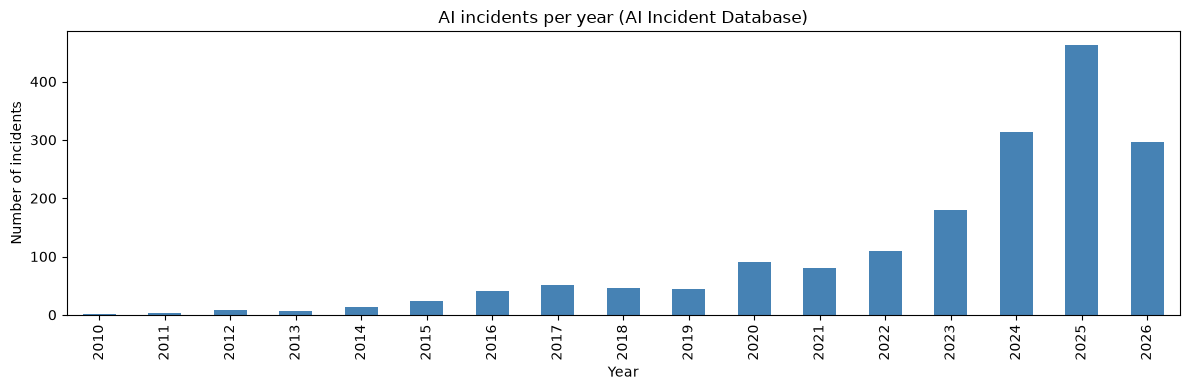

In [5]:
import matplotlib.pyplot as plt

df["year"] = df["date"].dt.year

per_year = df["year"].value_counts().sort_index()
per_year = per_year.reindex(range(2010, 2027), fill_value=0)
print(per_year)

per_year.plot(kind="bar", figsize=(12, 4), color="steelblue")
plt.title("AI incidents per year (AI Incident Database)")
plt.xlabel("Year")
plt.ylabel("Number of incidents")
plt.tight_layout()
plt.show()


## My notes (step 5)

- After 2020 the number of incidents grows very fast: 91 in 2020 and 463 in 2025, about 5 times more.
- 2026 looks lower (296), but the data stops on 30 October, so 2 months are missing. At the same speed the
  full year would be about 355. And incidents are often added to the database late, so the real number is
  probably higher.
- Part of the growth is probably more reporting: more news about AI after ChatGPT, and the database
  itself only started in 2020. But there are also many more AI systems in use now. I can't tell yet how
  much is real.
- Before 2010 there are only a few incidents, so I start the chart from 2010.

## 6. Which types of incidents are growing?

In [6]:
mit = pd.read_csv("data/mongodump_full_snapshot/classifications_MIT.csv")
print("MIT rows:", len(mit))

both = df.merge(mit, left_on="incident_id", right_on="Incident ID", how="inner")
print("Incidents with a risk type:", len(both))

both["Risk Domain"].value_counts()

MIT rows: 1498
Incidents with a risk type: 1498


Risk Domain
4. Malicious Actors & Misuse                      566
7. AI system safety, failures, and limitations    314
1. Discrimination and Toxicity                    244
3. Misinformation                                 196
2. Privacy & Security                             112
5. Human-Computer Interaction                      42
6. Socioeconomic & Environmental Harms             24
Name: count, dtype: int64

## 7. Incident types per year

Risk Domain  1. Discrimination and Toxicity  2. Privacy & Security  \
year                                                                 
2015                                      7                      3   
2016                                     16                      1   
2017                                     16                      9   
2018                                     14                      5   
2019                                     16                      6   
2020                                     32                      5   
2021                                     18                      5   
2022                                     25                     10   
2023                                     24                     12   
2024                                     30                     17   
2025                                     25                     24   

Risk Domain  3. Misinformation  4. Malicious Actors & Misuse  \
year                     

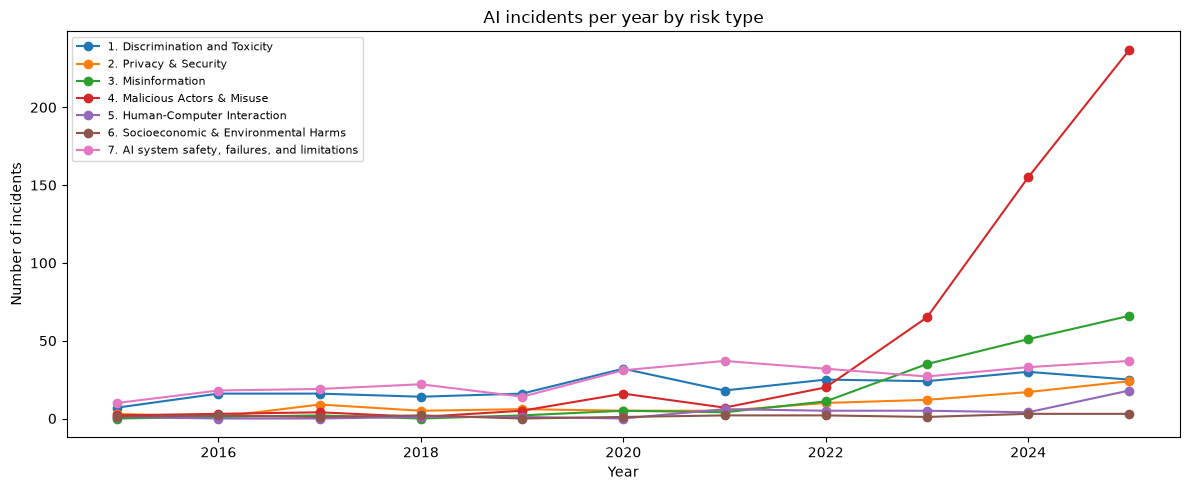

In [7]:
by_type = pd.crosstab(both["year"], both["Risk Domain"])
by_type = by_type.loc[2015:2025]
print(by_type)

by_type.plot(figsize=(12, 5), marker="o")
plt.title("AI incidents per year by risk type")
plt.xlabel("Year")
plt.ylabel("Number of incidents")
plt.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 8. How many incidents have a risk label each year?

In [8]:
labelled_ids = set(mit["Incident ID"])
df["has_label"] = df["incident_id"].isin(labelled_ids)

label_rate = df.groupby("year")["has_label"].mean().loc[2015:2026]
print((label_rate * 100).round(0))


year
2015    100.0
2016    100.0
2017     98.0
2018     98.0
2019     98.0
2020     99.0
2021     99.0
2022     96.0
2023     94.0
2024     94.0
2025     89.0
2026     34.0
Name: has_label, dtype: float64


## 9. What are the 2025 incidents about?

In [9]:
pd.set_option("display.max_colwidth", 120)

misuse_2025 = both[(both["year"] == 2025) & (both["Risk Domain"] == "4. Malicious Actors & Misuse")]
print("Misuse incidents in 2025:", len(misuse_2025))

misuse_2025[["incident_id", "title", "Risk Subdomain"]].sample(15, random_state=1)

Misuse incidents in 2025: 237


,incident_id,title,Risk Subdomain
1333,1345,Purported Deepfake Video Allegedly Used to Harass Washington State Patrol Trooper,"4.3. Fraud, scams, and targeted manipulation"
1156,1168,Purportedly AI-Generated Image of British Army Colonels Captured in Ukraine Reportedly Circulates in Russian Media,"4.1. Disinformation, surveillance, and influence at scale"
1083,1095,Alleged Russian-Linked Deepfake Campaign Misattributes Infrastructure Projects to Burkina Faso's Ibrahim Traoré,"4.1. Disinformation, surveillance, and influence at scale"
1100,1112,Scammer Reportedly Used AI Voice Clone of WCPO Cincinnati Meteorologist in Facebook Fraud Attempts,"4.3. Fraud, scams, and targeted manipulation"
1369,1381,"Purportedly AI-Generated TikTok Videos Reportedly Urged 'Polexit' Campaign, Prompting Polish Government Complaint to EU","4.1. Disinformation, surveillance, and influence at scale"
889,901,"Yahoo Boys Allegedly Used Deepfake Technology to Impersonate Brad Pitt and Defraud French Woman of $850,000 in Roman...","4.3. Fraud, scams, and targeted manipulation"
1098,1110,Alleged AI-Manipulated Video Uses Macau Chief Executive Sam Hou Fai's Likeness in Investment Scam,"4.3. Fraud, scams, and targeted manipulation"
933,945,"Two 16-Year-Old Students in Athens, Greece Allegedly Generated Nonconsensual Deepfake Pornography of Their Classmates","4.3. Fraud, scams, and targeted manipulation"
1141,1153,Purported Deepfake Video of Donald Trump at NATO Summit Allegedly Used in YouTube Crypto Scam,"4.3. Fraud, scams, and targeted manipulation"
1386,1398,"Purported Deepfake Video Reportedly Misrepresented CBS Anchor Doug Dunbar and Frisco, Texas, Stabbing Suspect Amid O...","4.1. Disinformation, surveillance, and influence at scale"


In [10]:
misuse_2025["Risk Subdomain"].value_counts()

Risk Subdomain
4.3. Fraud, scams, and targeted manipulation                   190
4.1. Disinformation, surveillance, and influence at scale       38
4.2. Cyberattacks, weapon development or use, and mass harm      9
Name: count, dtype: int64

In [11]:
hci_2025 = both[(both["year"] == 2025) & (both["Risk Domain"] == "5. Human-Computer Interaction")]
print("Human-Computer Interaction incidents in 2025:", len(hci_2025))

hci_2025[["incident_id", "title", "Risk Subdomain"]]

Human-Computer Interaction incidents in 2025: 18


,incident_id,title,Risk Subdomain
939,951,Character.AI Chatbots Allegedly Impersonating Licensed Therapists and Encouraging Harmful Behaviors,5.1. Overreliance and unsafe use
1059,1071,Student Reportedly Files Complaint Over Professor's Undisclosed Use of Generative AI at Northeastern University,5.1. Overreliance and unsafe use
1094,1106,"Chatbots Allegedly Reinforced Delusional Thinking in Several Reported Users, Leading to Real-World Harm",5.1. Overreliance and unsafe use
1139,1151,ChatGPT Reportedly Validated Autistic User's Faster-Than-Light Theory and Failed to Provide Grounding During Delusio...,5.1. Overreliance and unsafe use
1165,1177,"Purported AI Monitoring Software Reportedly Flags Unsent Joke Threat, Leading to Arizona Student Suspension",5.1. Overreliance and unsafe use
1168,1180,"Purported Meta AI Chatbot Persona 'Big sis Billie' Reportedly Engages in Romantic Roleplay and Provides Address, Lin...",5.1. Overreliance and unsafe use
1178,1190,Family Reportedly Discovers ChatGPT Logs Detailing Suicidal Ideation Prior to Daughter's Death,5.1. Overreliance and unsafe use
1180,1192,16-Year-Old Allegedly Received Suicide Method Guidance from ChatGPT Before Death,5.1. Overreliance and unsafe use
1192,1204,"ChatGPT Allegedly Reinforced Delusions Before Greenwich, Connecticut Murder-Suicide",5.1. Overreliance and unsafe use
1241,1253,Large-Scale Mental Health Crises Allegedly Associated with ChatGPT Interactions,5.1. Overreliance and unsafe use


## My notes on step 9

- **Misuse in 2025 is mostly fraud and scams** (190 of 237): deepfake videos and cloned voices of famous
  people used in investment scams, and fake sexual images of real people, including school children.
  The rest is mostly disinformation (38), for example fake videos in elections, and a few cyberattacks (9).
- **The Human-Computer Interaction incidents are mostly about chatbots** (mostly ChatGPT) and mental
  health: chatbots agreeing with people's delusions or not stopping conversations about suicide. MIT
  calls them "overreliance and unsafe use", but in many of them the problem seems to be how the chatbot
  behaved, not only how the person used it.
- Almost every title says "allegedly", "reportedly" or "purportedly", so many incidents are not confirmed.
- **What could get much worse:** fraud and disinformation at a much bigger scale as fake video and voice
  get cheaper and better, and chatbots that are more persuasive and that many people rely on for advice.